In [826]:
print('In the name of Allah')

In the name of Allah


In [827]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing, load_diabetes, load_breast_cancer, load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder,OneHotEncoder,LabelEncoder

In [828]:
pip install ucimlrepo

# Q1 The Income Trap

Adult Income (Census Income)

https://archive.ics.uci.edu/dataset/2/adult

Read about what 'capital-gain' and 'capital-loss' represent in US income tax filings before answering.

Theory

1. The 'capital-gain' column has ~91% of its values equal to exactly zero, with a few extreme values reaching over $99,000. Is this an outlier problem or a distributional problem? Justify your answer using the concept of the Normal Distribution from class.

2. If you apply StandardScaler (Z-score normalization) to 'capital-gain', what happens to the Z-scores of those extreme values? Why would a RobustScaler be more appropriate here?

3. Explain Winsorization. If you apply 5th–95th percentile Winsorization to 'hours-per-week', what are you assuming about the data-generating process, and what are the risks?

Practical

4. Load the dataset (it uses '?' for missing values — handle this first). Perform train-test split. Plot the distribution of 'capital-gain' using a KDE plot. Confirm the extreme skew visually.

5. Apply Winsorization (clip at 5th–95th percentile) to 'capital-gain' on the training set. Apply the SAME clipping bounds to the test set. Plot before/after KDE plots.

6. Apply RobustScaler to 'hours-per-week' and 'capital-gain' . Compare the scaled range with what StandardScaler would have produced. Which handles the outliers better? Justify numerically.

## Theory Solution :

1.  We know a normal distribution should be symmetric and bell shaped. But the given, 'capital-gain' column has 91 percent zero values and few very large values, which is over $99,000. Therefore, this might be a distributional problem, rather than just an outlier problem.

2. We know, Standard Scaler uses mean and std. In 'capital-gain' column the values has 91 percent zero values and few value has extreme outliers.So, the resulting Standard Scaler can be distorted.On the otherhand, Robust Scaler uses median and IQR. Robust Scaler can fit in skewed columns efficiently.

3. If we apply 5th–95th percentile Winsorization to 'hours-per-week', that means all values which is less than 5th percentile convert to 5th percentile and values above 95th percentile are set to 95th percentile. Winsorization method is better when the outlier is not defined. One drawbacks in Winsorization is to identify x is difficult.

In [829]:
# Practical

# 4

from ucimlrepo import fetch_ucirepo

# fetch dataset
adult = fetch_ucirepo(id=2)

# data (as pandas dataframes)

df = adult.data.features
# y = adult.data.targets

# metadata
print(adult.metadata)

# variable information
print(adult.variables)


{'uci_id': 2, 'name': 'Adult', 'repository_url': 'https://archive.ics.uci.edu/dataset/2/adult', 'data_url': 'https://archive.ics.uci.edu/static/public/2/data.csv', 'abstract': 'Predict whether annual income of an individual exceeds $50K/yr based on census data. Also known as "Census Income" dataset. ', 'area': 'Social Science', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 48842, 'num_features': 14, 'feature_types': ['Categorical', 'Integer'], 'demographics': ['Age', 'Income', 'Education Level', 'Other', 'Race', 'Sex'], 'target_col': ['income'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1996, 'last_updated': 'Tue Sep 24 2024', 'dataset_doi': '10.24432/C5XW20', 'creators': ['Barry Becker', 'Ronny Kohavi'], 'intro_paper': None, 'additional_info': {'summary': "Extraction was done by Barry Becker from the 1994 Census database.  A set of reasonably clean records was extracted using the fol

In [830]:
df

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,39,Private,215419,Bachelors,13,Divorced,Prof-specialty,Not-in-family,White,Female,0,0,36,United-States
48838,64,NaN,321403,HS-grad,9,Widowed,NaN,Other-relative,Black,Male,0,0,40,United-States
48839,38,Private,374983,Bachelors,13,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,50,United-States
48840,44,Private,83891,Bachelors,13,Divorced,Adm-clerical,Own-child,Asian-Pac-Islander,Male,5455,0,40,United-States


In [831]:
df.isnull().sum()

,0
age,0
workclass,963
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,966
relationship,0
race,0
sex,0


In [832]:
( df == '?' ).sum()

,0
age,0
workclass,1836
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,1843
relationship,0
race,0
sex,0


In [833]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       47879 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education-num   48842 non-null  int64 
 5   marital-status  48842 non-null  object
 6   occupation      47876 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital-gain    48842 non-null  int64 
 11  capital-loss    48842 non-null  int64 
 12  hours-per-week  48842 non-null  int64 
 13  native-country  48568 non-null  object
dtypes: int64(6), object(8)
memory usage: 5.2+ MB


In [834]:
df = df.replace('?', np.nan)

In [835]:
df.isnull().sum()

,0
age,0
workclass,2799
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,2809
relationship,0
race,0
sex,0


In [836]:
df[['workclass', 'occupation', 'native-country']]

,workclass,occupation,native-country
0,State-gov,Adm-clerical,United-States
1,Self-emp-not-inc,Exec-managerial,United-States
2,Private,Handlers-cleaners,United-States
3,Private,Handlers-cleaners,United-States
4,Private,Prof-specialty,Cuba
...,...,...,...
48837,Private,Prof-specialty,United-States
48838,NaN,NaN,United-States
48839,Private,Prof-specialty,United-States
48840,Private,Adm-clerical,United-States


In [837]:
from sklearn.impute import SimpleImputer


imputer_transformer = ColumnTransformer(
    transformers = [
        ( 'all', SimpleImputer(missing_values = np.nan, strategy = 'most_frequent'), ['workclass', 'occupation', 'native-country'] )
    ],
    remainder = 'passthrough',
    verbose_feature_names_out = False
)

imputer_transformer.set_output(transform = 'pandas')

imputer_transformer.fit(df)

df = imputer_transformer.transform(df)


In [838]:
df.isnull().sum()

,0
workclass,0
occupation,0
native-country,0
age,0
fnlwgt,0
education,0
education-num,0
marital-status,0
relationship,0
race,0


In [839]:
df[['workclass', 'occupation', 'native-country']].sample(10)

,workclass,occupation,native-country
43003,Self-emp-inc,Craft-repair,United-States
45390,Private,Other-service,United-States
41914,Private,Exec-managerial,United-States
16818,State-gov,Tech-support,United-States
16664,Local-gov,Transport-moving,United-States
41294,Private,Craft-repair,Laos
7447,Self-emp-not-inc,Protective-serv,United-States
9466,Private,Transport-moving,United-States
15189,Private,Exec-managerial,United-States
680,Local-gov,Protective-serv,United-States


In [840]:
X = df
y = adult.data.targets

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [841]:
X_train.isnull().sum()

,0
workclass,0
occupation,0
native-country,0
age,0
fnlwgt,0
education,0
education-num,0
marital-status,0
relationship,0
race,0


In [842]:
y_train.isnull().sum()
y_test.isnull().sum()

,0
income,0


<Axes: xlabel='capital-gain', ylabel='Density'>

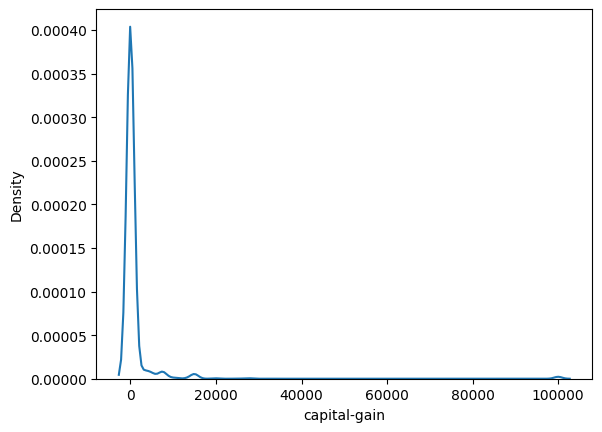

In [843]:
sns.kdeplot(data = X_train, x = X_train['capital-gain'])

In [844]:
X_train['capital-gain'].skew()

np.float64(11.827158640205797)

In [845]:
# 5.

# print(f'Maximum value of X_train : {X_train['capital-gain'].max()}')

x = 5
x = x / 100

min_range_X_train = X_train['capital-gain'].quantile(x)

max_range_X_train = X_train['capital-gain'].quantile(1 - x)

print(f'Min range of X_train : {min_range_X_train} and Max range of X_train : {max_range_X_train}')

X_train_kde = X_train.copy()

X_train_kde['capital-gain'] = X_train_kde['capital-gain'].clip(min_range_X_train, max_range_X_train)


min_range_X_test = X_test['capital-gain'].quantile(x)

max_range_X_test = X_test['capital-gain'].quantile(1 - x)

print(f'Min range of X_test : {min_range_X_test} and Max range of X_test : {max_range_X_test}')

X_test_kde = X_test.copy()

X_test_kde['capital-gain'] = X_test_kde['capital-gain'].clip(min_range_X_test, max_range_X_test)



Min range of X_train : 0.0 and Max range of X_train : 5013.0
Min range of X_test : 0.0 and Max range of X_test : 4650.0


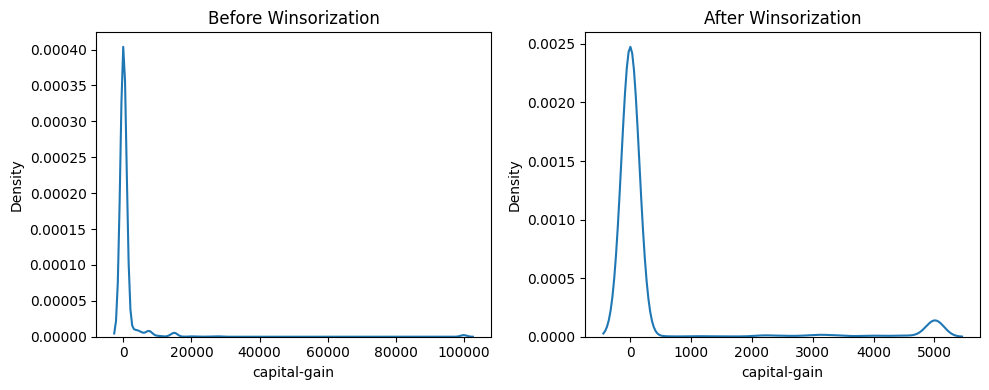

In [846]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

sns.kdeplot( data = X_train, x = X_train['capital-gain'], ax = ax[0] )

ax[0].set_title('Before Winsorization')

sns.kdeplot(data = X_train_kde, x = X_train_kde['capital-gain'], ax = ax[1] )

ax[1].set_title('After Winsorization')

plt.tight_layout()
plt.show()


In [847]:
# 6

X_train[['hours-per-week', 'capital-gain']].sample(10)


,hours-per-week,capital-gain
41278,40,0
33786,23,0
7764,40,0
42181,60,0
20550,15,0
28799,40,0
31113,5,0
12172,40,0
35682,80,0
26743,40,0


In [848]:
# Robust Scaler on hours-per-week

cols = ['capital-gain', 'hours-per-week']

rs = RobustScaler()

rs.fit(X_train[cols])

X_train_rs = rs.transform(X_train[cols])

X_train_rs = pd.DataFrame(X_train_rs, columns = cols)

X_train_rs.describe()

,capital-gain,hours-per-week
count,39073.000000,39073.000000
mean,1091.418038,0.080158
std,7500.039346,2.478734
min,0.000000,-7.800000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,0.000000,1.000000
max,99999.000000,11.800000


In [849]:
# Standard Scaler on hours-per-week

cols = ['capital-gain', 'hours-per-week']

ss = StandardScaler()

ss.fit(X_train[cols])

X_train_ss = ss.transform(X_train[cols])

X_train_ss = pd.DataFrame(X_train_ss, columns = cols)

X_train_ss.describe()

,capital-gain,hours-per-week
count,3.907300e+04,3.907300e+04
mean,1.645743e-17,6.382937e-17
std,1.000013e+00,1.000013e+00
min,-1.455235e-01,-3.179147e+00
25%,-1.455235e-01,-3.233856e-02
50%,-1.455235e-01,-3.233856e-02
75%,-1.455235e-01,3.710984e-01
max,1.318778e+01,4.728217e+00


we can see, Standard Scaler affected by extreme values because it uses mean and std. The large values in 'capital-gain' column still reamins and it contains outliers. On the otherhand, Robust Scaler uses median and IQR, which makes less sensitive to outliers.

# Q2 The Churning Machine

📦 DATASET

Telco Customer Churn https://www.kaggle.com/datasets/blastchar/telco-customer-churn

what 'churn' means in the telecom industry and why it is a critical business KPI before starting.

Theory

7. The target column 'Churn' has roughly 73% 'No' and 27% 'Yes'. Explain why this class imbalance matters for a model. If you don't address it, what kind of predictions might the model make?

8. The 'TotalCharges' column is stored as a string (object) despite being numeric. What is the likely reason? (Hint: look at what happens with customers who have 0 tenure.) What preprocessing step is needed?

9. From an EDA perspective, what is the difference between a countplot with hue and a grouped bar chart (barplot)? When would you use each for this dataset?

Practical

10. Load the dataset. Fix the 'TotalCharges' data type issue. Confirm by checking df.info() before and after.

11. Perform full univariate analysis: (a) For all categorical columns, create countplots; (b) For all numerical columns, plot histograms with kde=True. Write at least one business insight per plot.

12. Perform multivariate analysis: (a) Create a countplot of 'Contract' vs 'Churn' with hue; (b) Create a KDE plot of 'tenure' grouped by 'Churn';Describe two findings that would help a business reduce churn.

# Theory Solution :

7. We can see target column 'Churn' has 73% 'No' and 27% 'Yes'. This is class imbalance because one class appears more than 70% than the others.
We know that, ML models tries to maximize the overall accuracy. As most customers belongs to 'No', the model also learn to predict 'No' most of the time.

8. From the dataset we can see the column is saved as object. But the 'TotalCharges' should contain numeric values. The reason behind might be some customer has No billing history. For these customers, 'TotalCharges' field contains blank spaces.
Because of this, pandas treats the entire column as object.
We have to use, pd.to_numeric(df['TotalCharges'], errors = 'coerce')
This will converts invalid values into NaN.

9. The countplot with hues displays the frequency in each category. And the boxplot shows statistic as Mean, Median and percentage. From the perspective of Exploratory Data Analysis(EDA), we will use Counplot with hue when we want to compare something and Barplot is usefull when we want to see mean, median, average or outliers.

In [850]:
# Practical

# 10

df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

df

df.info()

print('\n\n\n')

print(f'Before Conversion Missing values : {df['TotalCharges'].isnull().sum()}')

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors = 'coerce')

print(f'After Conversion Missing values : {df['TotalCharges'].isnull().sum()}')

df['TotalCharges'].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [851]:
# 11

df['TotalCharges'] = df['TotalCharges'].fillna(0)

# df['TotalCharges'].isnull().sum()

df['customerID'] = df['customerID'].astype(str).str[0]

df['customerID'] = pd.to_numeric(df['customerID'], errors = 'coerce')

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   int64  
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [852]:
numeric_df = df.select_dtypes(include='number').columns.tolist()

print(f'Numeric Columns : {numeric_df}')

categorical_df = df.select_dtypes(include = ['object', 'category']).columns.tolist()

print(f'Categorical Columns : {categorical_df}')

Numeric Columns : ['customerID', 'SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical Columns : ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']


In [853]:
df['Churn'].unique() # SeniorCitizen is not Numerical

array(['No', 'Yes'], dtype=object)

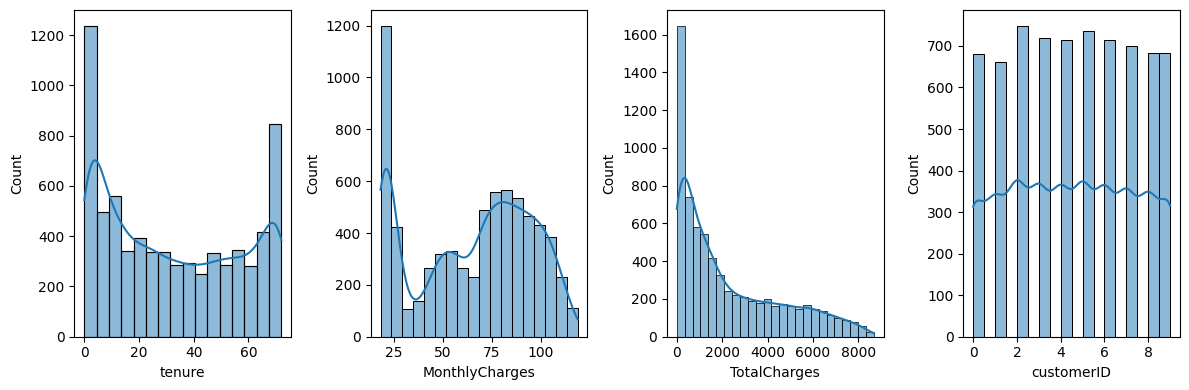

In [854]:
fig, ax = plt.subplots(1, 4, figsize=(12, 4))

sns.histplot(data = df, x = 'tenure', kde = True, ax = ax[0])

sns.histplot(data = df, x = 'MonthlyCharges', kde = True, ax = ax[1])

sns.histplot(data = df, x = 'TotalCharges', kde = True, ax = ax[2])

sns.histplot(data = df, x = 'customerID', kde = True, ax = ax[3])

plt.tight_layout()
plt.show()

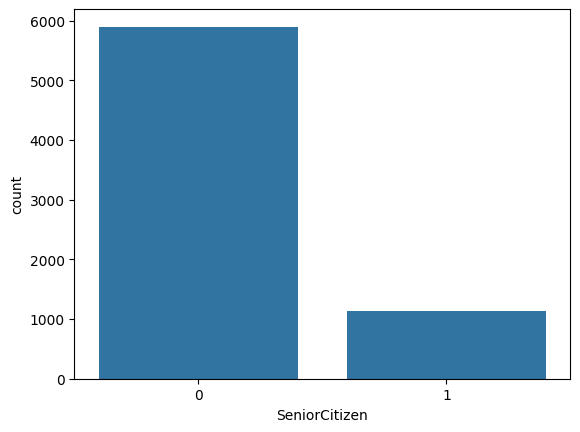

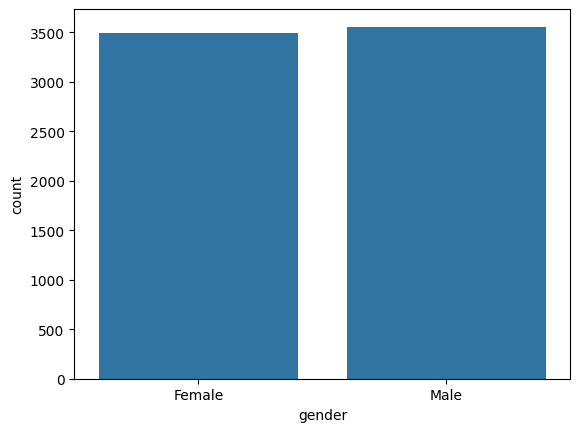

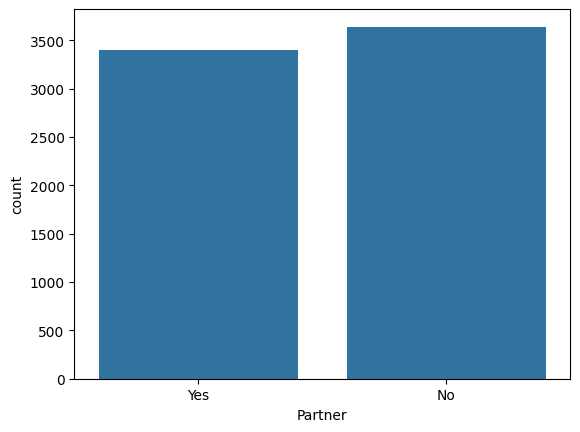

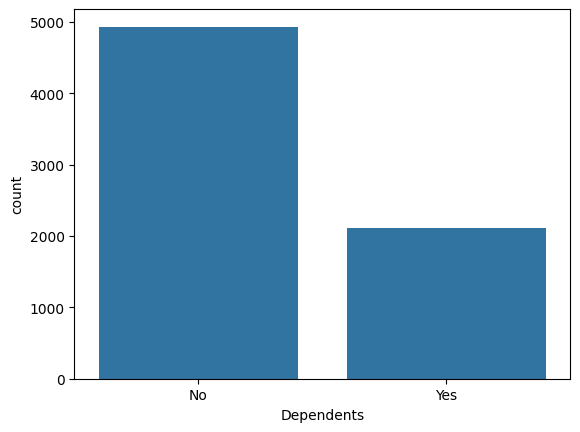

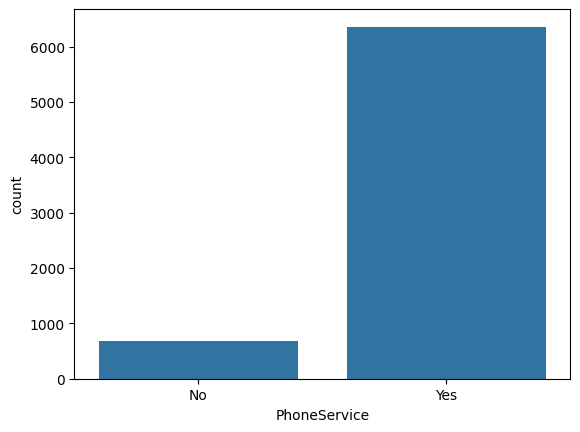

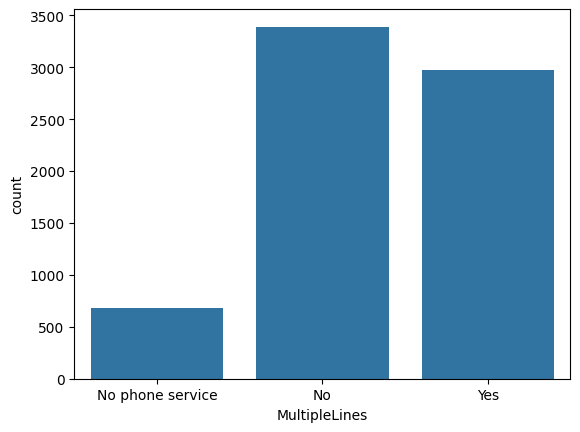

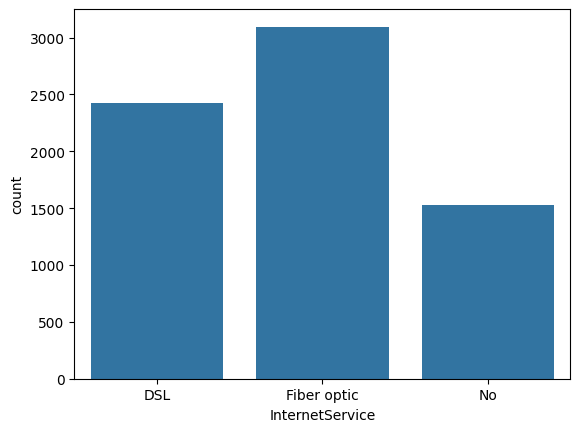

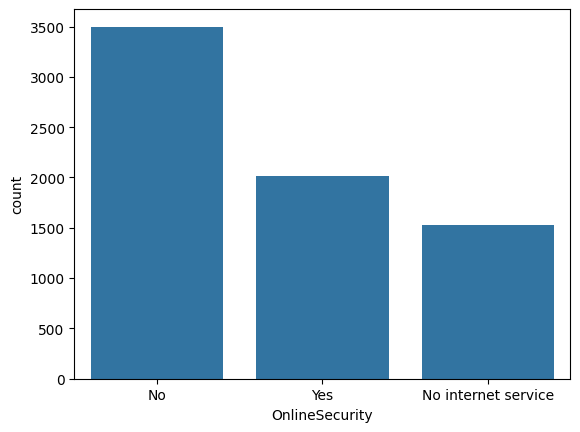

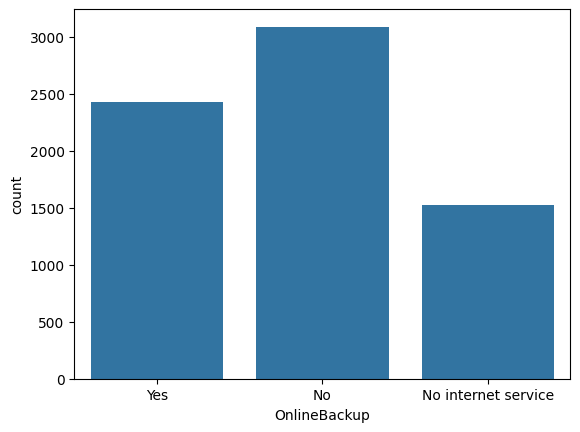

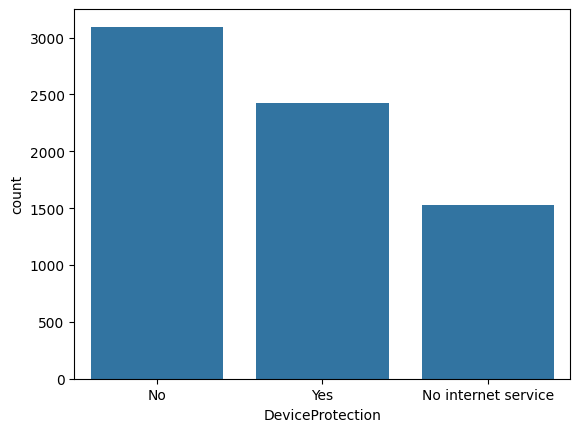

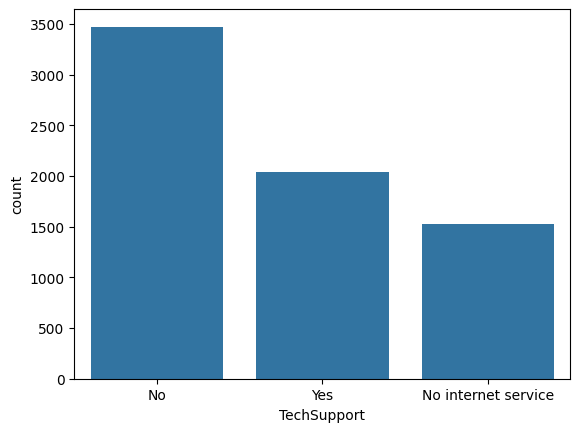

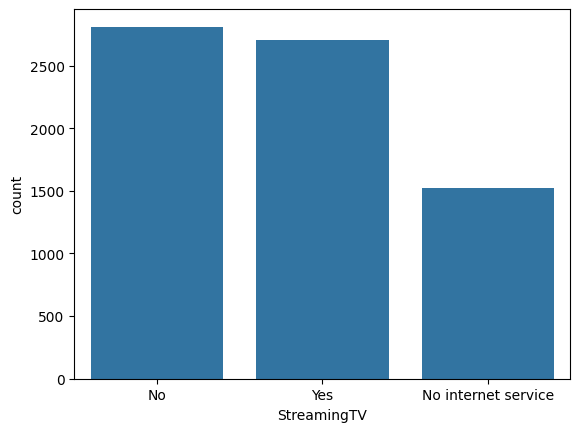

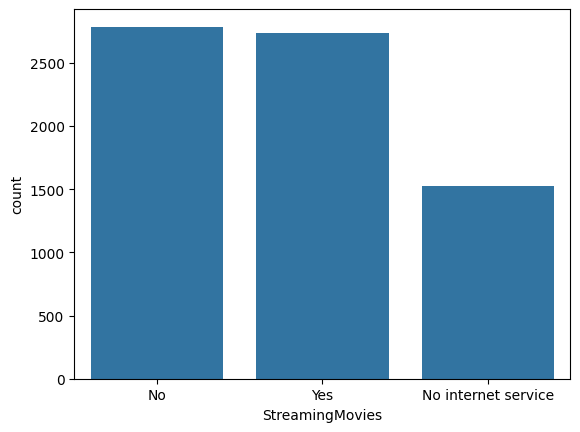

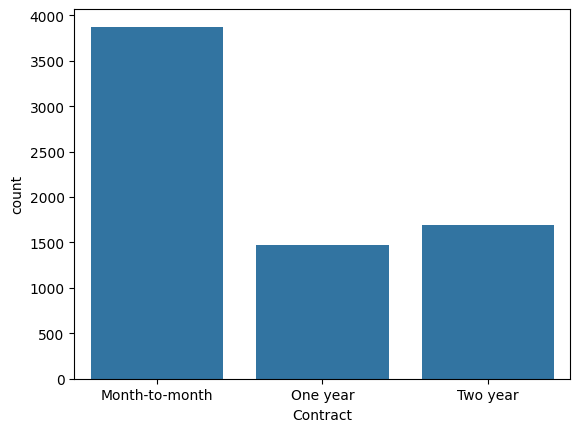

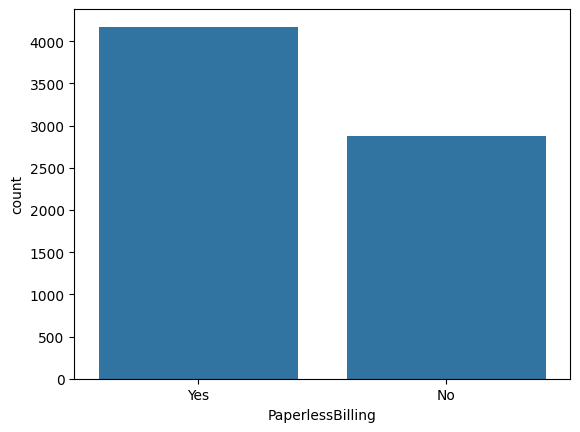

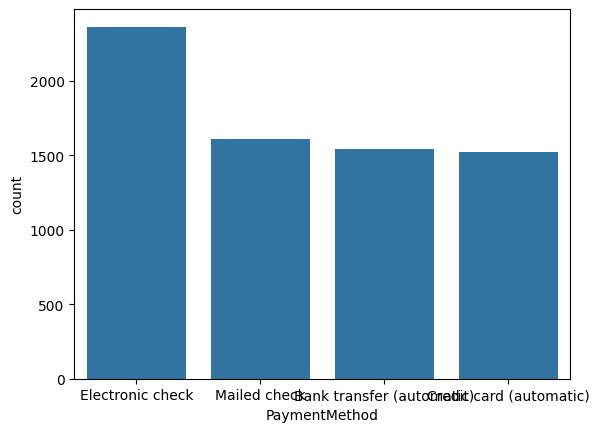

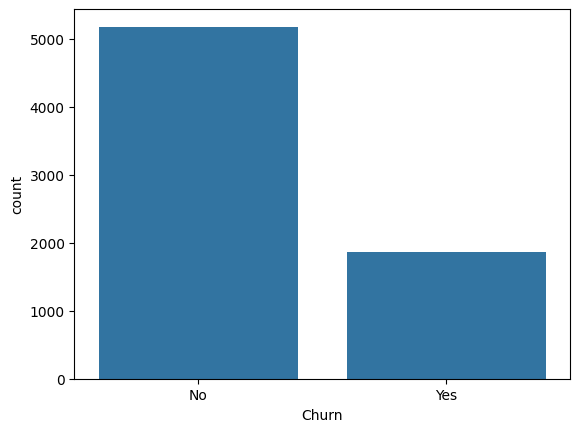

In [855]:
Categorical = ['SeniorCitizen', 'gender', 'Partner', 'Dependents',
                       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
                       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
                       'PaperlessBilling', 'PaymentMethod', 'Churn']


for col in Categorical :
  sns.countplot(data = df, x = col)
  plt.show()


In [856]:
df['customerID'].nunique()

10

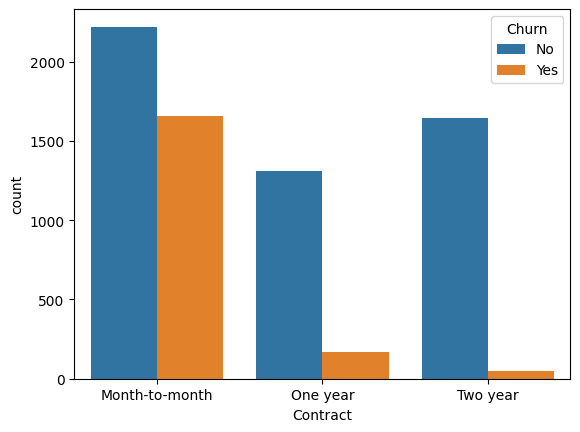

In [857]:
# 12

# a

sns.countplot(data = df, x = 'Contract', hue = 'Churn')

plt.show()

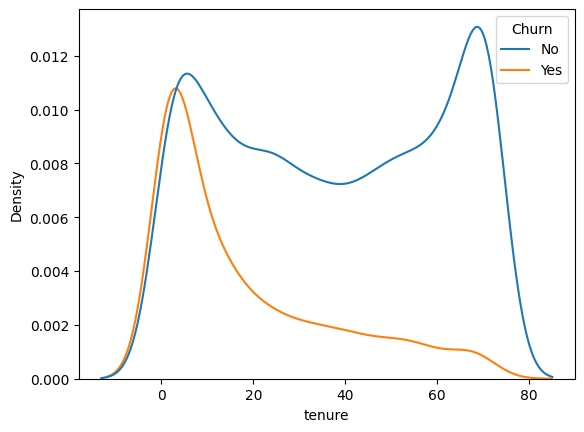

In [858]:
# b

sns.kdeplot(data = df, x = 'tenure', hue = 'Churn')

plt.show()

# Q3 Z-Scores & The Empirical Rule in the Wild

Medical Cost Personal Dataset

https://www.kaggle.com/datasets/mirichoi0218/insurance

Research what BMI (Body Mass Index) is, what the clinical thresholds are(underweight, normal, overweight, obese), and why it might be a critical feature for insurance charges.

Theory

13. According to the Empirical Rule (68-95-99.7), if BMI is approximately normally distributed with mean=30 and std=6, what percentage of people have BMI above 42?

14. You detect that the 'charges' column has a Z-score outlier threshold at |Z| > 3. A student removes ALL rows with |Z| > 3 before the train-test split. Identify two problems with this approach.

15. Why might the IQR method detect different outliers than the Z-score method on the same column? In which situation is each method preferred?

Practical

16. Load the dataset. Verify whether 'bmi' follows an approximately normal distribution: (a) Plot a KDE plot; (b) Compute skewness

17. For the 'charges' column: (a) Identify outliers using the IQR method (b) Identify outliers using the Z-score method (c) Compare how many outliers each method detects. Which is more conservative?

18. Create a new feature 'bmi_category' using the WHO thresholds (Underweight < 18.5, Normal 18.5–24.9, Overweight 25–29.9, Obese >= 30). Then use a barplot to visualize average 'charges' per BMI category. What pattern do you see?


# Theory :

13. Given, mean = 30, std = 6

    z = ( 42 - 30 ) / 6 = 2

    Z-score is 2. So, BMI is exactly 2 standard deviation above the mean.
    According to Empircal Rule, 95% lie within +- 2 alpha. So, 5% lie outside +- 2 alpha. So 5% of people have BMI above 42.

14. The two major problem with te following approach is :
    1. Data Leakage :

        As Z-score outlier threshold at |Z| > 3 in main dataset. It allows information from the future test set to influence pre processing decision causing data leakage.

    2.  Losing of Important information :

        As in the dataset, applied z-sore before splitting and the extreme outliers also removed. It might remove the important information regarding the data.
        
15. z-score depends on mean and standard deviation. On the oterhand, IQR method uses, IQR = Q3 - Q1 and outlier limits : lower = Q1 - 1.5 * IQR and upper = Q3 + 1.5 * IQR. It depends on quartiles instead of mean and std.

Thats why the IQR method detects different outliers than z-score.

Whe the data is normally distributed, we use z-score. And when the data contains extreme outliers or skewed we use IQR.

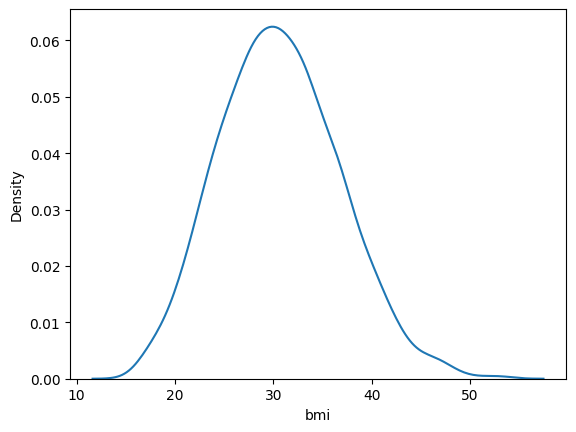





Skewness of BMI : 0.2840471105987448


In [859]:
# Practical

# 16

df = pd.read_csv('insurance.csv')

df

# a
sns.kdeplot(data = df, x = 'bmi')

plt.show()

print('\n\n\n')

# b

print(f'Skewness of BMI : {df['bmi'].skew()}')


In [860]:
# a

# IQR

Q1 = df['charges'].quantile(0.25)
Q3 = df['charges'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

iqr_outliers = df[( df['charges'] < lower ) | ( df['charges'] > upper ) ]

# Z-score

mean_charges = df['charges'].mean()
std_charges = df['charges'].std()

df['z_score'] = ( df['charges'] - mean_charges ) / std_charges

zscore_outliers = df[abs( df['z_score'] ) > 3]


print(f'IQR Outliers : {iqr_outliers.shape[0]}')
print(f'Z-score Outliers : {zscore_outliers.shape[0]}')



IQR Outliers : 139
Z-score Outliers : 7


Here, the IQR method detected more outliers than z-score. So, z-score is more conservative.

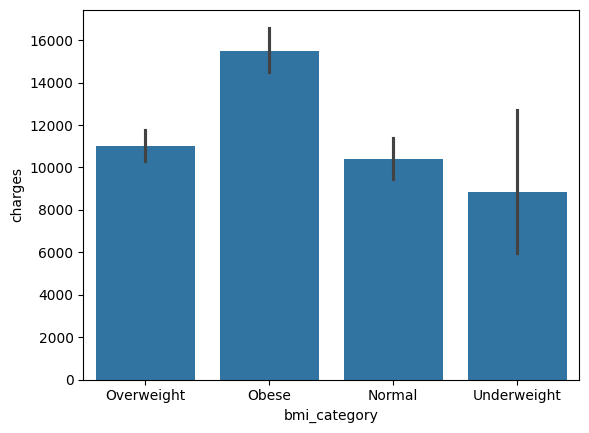

In [861]:
# 18

def bmi_cat(bmi) :

  if bmi < 18.5 :
    return 'Underweight'
  elif bmi <= 24.9 :
    return 'Normal'
  elif bmi <= 29.9 :
    return 'Overweight'
  else :
    return 'Obese'


df['bmi_category'] = df['bmi'].apply(bmi_cat)

df[['bmi', 'bmi_category']].sample(10)

sns.barplot( data = df, x = 'bmi_category', y = 'charges' )
plt.show()


From the barplot, we can see charges is increasing with BMI.

# Q4 The Big City Problem — Outlier Handling at Scale

DATASET

NYC Taxi Trip Duration https://www.kaggle.com/c/nyc-taxi-trip-duration


Theory

19. A trip duration of 86,400 seconds (24 hours) exists in this dataset. Is this a data entry error, a real event, or something else? How would you decide programmatically AND using domain knowledge?

20. After removing outliers from the training set, should you also remove outliers from the test set? Justify your answer carefully — think about what a test set represents in a real production scenario.

Practical


21. Load the dataset (sample 20k rows). Convert 'pickup_datetime' to datetime and extract hour, day-of-week, and month as new features. Check: are there any biologically impossible trip durations (e.g., <= 0 seconds or > 24 hours)?

22. Apply IQR-based outlier detection to 'trip_duration'. Print how many outliers were detected and what % of the data they represent. Remove them from the training set ONLY.

23. Create a scatter plot of pickup_longitude vs pickup_latitude, coloring points by trip_duration. Do the outlier trips cluster in any particular geographic area? What does that suggest?


# Theory

19. A trip duration of 86,400 seconds (24 hours) exists in this dataset. This is a data entry error.

20. After removing outliers from the training set, we should not remove outliers from the test set. The test set should represent real world future data, which includes unusual cases too. If we remove outliers from the test set, we will never know if our model performs on unusual data. Our predication will be less realistic.



<class 'pandas.core.frame.DataFrame'>
Index: 20000 entries, 67250 to 108734
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  20000 non-null  object 
 1   vendor_id           20000 non-null  int64  
 2   pickup_datetime     20000 non-null  object 
 3   dropoff_datetime    20000 non-null  object 
 4   passenger_count     20000 non-null  int64  
 5   pickup_longitude    20000 non-null  float64
 6   pickup_latitude     20000 non-null  float64
 7   dropoff_longitude   20000 non-null  float64
 8   dropoff_latitude    20000 non-null  float64
 9   store_and_fwd_flag  20000 non-null  object 
 10  trip_duration       20000 non-null  int64  
dtypes: float64(4), int64(3), object(4)
memory usage: 1.8+ MB
Trip duration less than 0 : Empty DataFrame
Columns: [id, vendor_id, pickup_datetime, dropoff_datetime, passenger_count, pickup_longitude, pickup_latitude, dropoff_longitude, dropoff_latitude,

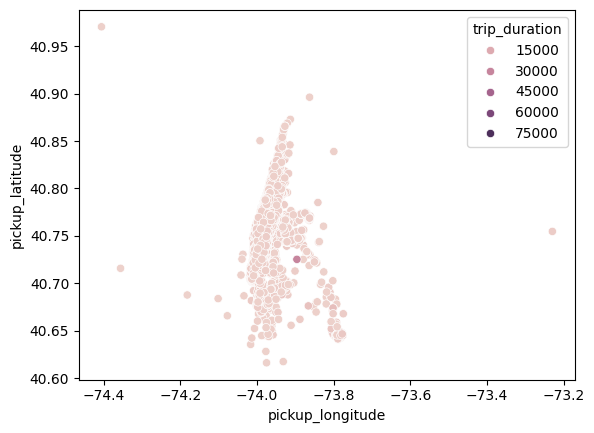

In [862]:
# Practical

# 21

df = pd.read_csv('NYC.csv').sample(n=20000, random_state=42)

df

df.info()

df['pickup_datetime'] = pd.to_datetime(df['dropoff_datetime'])

df['pickup_datetime']

df['pickup_hour'] = df['pickup_datetime'].dt.hour

df['pickup_hour']

df['pickup_dayofweek'] = df['pickup_datetime'].dt.dayofweek

df['pickup_dayofweek']

df['pickup_month'] = df['pickup_datetime'].dt.month

df['pickup_month']

invalid_0 = df[df['trip_duration'] <= 0 ]

print(f'Trip duration less than 0 : {invalid_0}')

invalid_24 = df[df['trip_duration'] > 86000 ]

print(f'Trip duration greater than 24 hours : \n{invalid_24}')

# 22

X = df.drop('trip_duration', axis = 1)

y = df['trip_duration']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)


# Applying IQR on trip_duration

Q1 = y_train.quantile(0.25)
Q3 = y_train.quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = y_train[ ( y_train < lower ) | ( y_train > upper ) ]

print(f'Total outliers : {len(outliers)}')

percent_outliers = round( ( len(outliers) / len(y_train) ) * 100, 2)

print(f'Percentage of outliers : {percent_outliers}%')


print(f'Maximum of y_train L: {y_train.max()}')

remove = ( y_train >= lower ) & ( y_train <= upper )

y_train_clean = X_train[remove]

y_train_clean

# 23

sns.scatterplot( data = df, x = 'pickup_longitude', y = 'pickup_latitude', hue = 'trip_duration' )

plt.show()

Yes, In this dataset, outlier trips often tend to show some geographic clustering, but not always in a single fixed location.

# Q5 Happiness by the Numbers — Full EDA Story

World Happiness Report 2023

Kaggle: https://www.kaggle.com/datasets/ajaypalsinghlo/world-happiness-report-2021

🧠 Theory

24. The 'Logged GDP per capita' column already has a log transformation applied. Why might the original GDP per capita have been log-transformed before inclusion in this report? What distribution property does log-transformation fix?
( Optional : Haven’t covered in the module , you can study it by yourself. We will cover it if it seems necessary )

25. You are asked to predict a country's happiness score. You have 'Social support', 'Healthy life expectancy', and 'Freedom to make life choices' as features. Explain conceptually whether you expect these will impact a man happiness score

26. A student concludes from a scatterplot that 'high GDP causes high happiness'. Critique this conclusion. Explain your thoughts

🧪 Practical

27. Load the dataset. Identify the top 10 and bottom 10 happiest countries. Create a horizontal bar chart showing both groups side-by-side with different colors.

28. Create a scatterplot of 'Logged GDP per capita' vs 'Ladder score'. Add a regression line using sns.regplot().

29. Perform regional analysis: group by 'Regional indicator' and compute the mean of all numeric columns. Visualize mean happiness by region using a barplot sorted by score. Which region has the highest variance in happiness? Use a boxplot to verify.



# Theory

24. GDP per capita have been log-transformed because it contains very high right skewed value. Thats why GDP per capita is log-transformded.

    It removed right skewness and make it stable for modeling.

25. I think the following features 'Social support', 'Healthy life expectancy', and 'Freedom to make life choices' can predicts a country's happiness score.

26. 'high GDP causes high happiness', This conclusion is not correct. Because scatterplot shows relationship, not the cause.
And i think high GDP is a option of make happiness but it does not directly make some happy.

In [863]:
df = pd.read_csv('world-happiness-report-2021.csv')

df

,Country name,Regional indicator,Ladder score,Standard error of ladder score,upperwhisker,lowerwhisker,Logged GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption,Ladder score in Dystopia,Explained by: Log GDP per capita,Explained by: Social support,Explained by: Healthy life expectancy,Explained by: Freedom to make life choices,Explained by: Generosity,Explained by: Perceptions of corruption,Dystopia + residual
0,Finland,Western Europe,7.842,0.032,7.904,7.780,10.775,0.954,72.000,0.949,-0.098,0.186,2.43,1.446,1.106,0.741,0.691,0.124,0.481,3.253
1,Denmark,Western Europe,7.620,0.035,7.687,7.552,10.933,0.954,72.700,0.946,0.030,0.179,2.43,1.502,1.108,0.763,0.686,0.208,0.485,2.868
2,Switzerland,Western Europe,7.571,0.036,7.643,7.500,11.117,0.942,74.400,0.919,0.025,0.292,2.43,1.566,1.079,0.816,0.653,0.204,0.413,2.839
3,Iceland,Western Europe,7.554,0.059,7.670,7.438,10.878,0.983,73.000,0.955,0.160,0.673,2.43,1.482,1.172,0.772,0.698,0.293,0.170,2.967
4,Netherlands,Western Europe,7.464,0.027,7.518,7.410,10.932,0.942,72.400,0.913,0.175,0.338,2.43,1.501,1.079,0.753,0.647,0.302,0.384,2.798
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
144,Lesotho,Sub-Saharan Africa,3.512,0.120,3.748,3.276,7.926,0.787,48.700,0.715,-0.131,0.915,2.43,0.451,0.731,0.007,0.405,0.103,0.015,1.800
145,Botswana,Sub-Saharan Africa,3.467,0.074,3.611,3.322,9.782,0.784,59.269,0.824,-0.246,0.801,2.43,1.099,0.724,0.340,0.539,0.027,0.088,0.648
146,Rwanda,Sub-Saharan Africa,3.415,0.068,3.548,3.282,7.676,0.552,61.400,0.897,0.061,0.167,2.43,0.364,0.202,0.407,0.627,0.227,0.493,1.095
147,Zimbabwe,Sub-Saharan Africa,3.145,0.058,3.259,3.030,7.943,0.750,56.201,0.677,-0.047,0.821,2.43,0.457,0.649,0.243,0.359,0.157,0.075,1.205


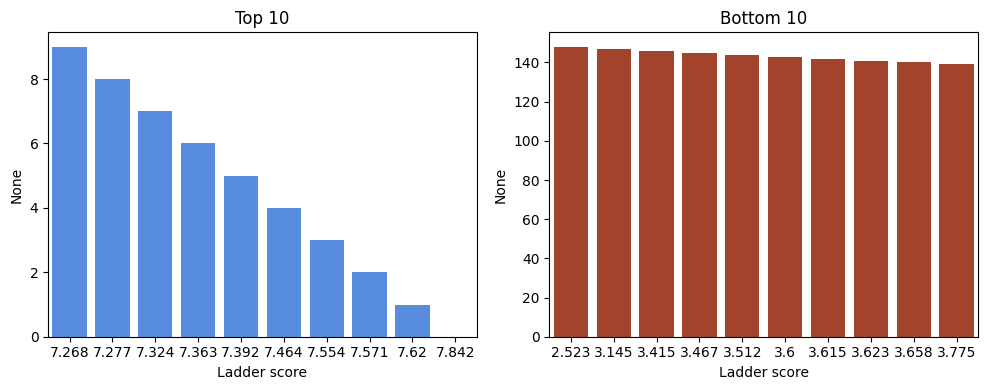

In [864]:
# 27

# Ladder score

top10 = df.nlargest(10, 'Ladder score')

bottom10 = df.nsmallest(10, 'Ladder score')

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

sns.barplot(data = top10, x = 'Ladder score', y = top10.index, ax = ax[0], color = '#4287f5')

ax[0].set_title('Top 10')

sns.barplot(data = bottom10, x = 'Ladder score', y = bottom10.index, ax = ax[1], color = '#b5371b')

ax[1].set_title('Bottom 10')

plt.tight_layout()
plt.show()


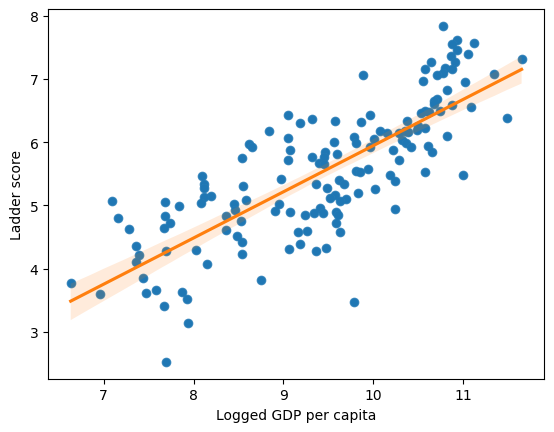

In [865]:
# 28

sns.scatterplot( data = df, x = 'Logged GDP per capita', y = 'Ladder score' )

sns.regplot( data = df, x = 'Logged GDP per capita', y = 'Ladder score', line_kws={"color": "C1"} )

plt.show()

In [866]:
# 29

region_mean = df.groupby('Regional indicator').mean(numeric_only=True)

region_mean

region_mean_sort = region_mean.sort_values( by = 'Ladder score', ascending = False ).reset_index()

region_mean_sort[['Regional indicator', 'Ladder score']].max()

,0
Regional indicator,Western Europe
Ladder score,7.1285


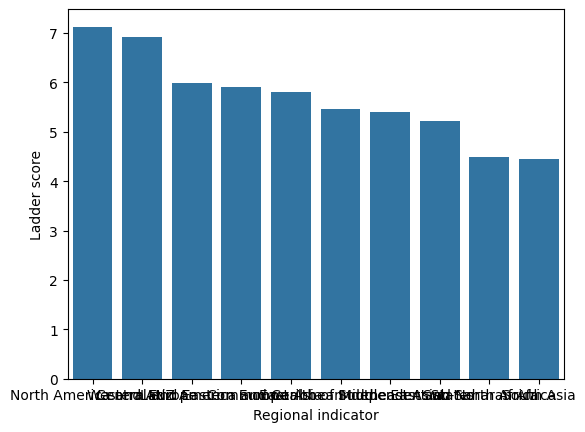

In [867]:
sns.barplot( data = region_mean_sort, x = 'Regional indicator', y = 'Ladder score' )

plt.show()

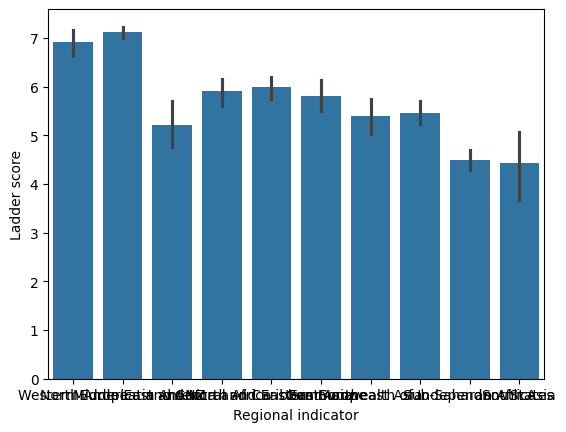

In [868]:
sns.barplot( data = df, x = 'Regional indicator', y = 'Ladder score' )

plt.show()

In [869]:
df[['Regional indicator', 'Ladder score']].max()

,0
Regional indicator,Western Europe
Ladder score,7.842


SURPRISE BONUS CHALLENGE

The End-to-End Pipeline Challenge

Pick ANY one of the 5 datasets above. Build a complete, end-to-end sklearn ColumnTransformer that:

• Handles missing values with the correct strategy for each column type

• Encodes all categorical features appropriately for the model
• Applies the right scaler (Standard vs. Robust — justify your choice)

• Handles outliers using either Zscore , IQR clipping or Winsorization (before the pipeline)


In [870]:
# I will solve the Adult Income

from ucimlrepo import fetch_ucirepo

# fetch dataset
adult = fetch_ucirepo(id=2)

# data (as pandas dataframes)

df = adult.data.features
y = adult.data.targets


In [871]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       47879 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education-num   48842 non-null  int64 
 5   marital-status  48842 non-null  object
 6   occupation      47876 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital-gain    48842 non-null  int64 
 11  capital-loss    48842 non-null  int64 
 12  hours-per-week  48842 non-null  int64 
 13  native-country  48568 non-null  object
dtypes: int64(6), object(8)
memory usage: 5.2+ MB


In [872]:
df.isnull().sum()

,0
age,0
workclass,963
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,966
relationship,0
race,0
sex,0


In [873]:
( df == '?' ).sum()

,0
age,0
workclass,1836
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,1843
relationship,0
race,0
sex,0


In [874]:
df = df.replace('?', np.nan)

In [875]:
df.isnull().sum()

,0
age,0
workclass,2799
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,2809
relationship,0
race,0
sex,0


In [876]:
df[['workclass', 'occupation', 'native-country']]

,workclass,occupation,native-country
0,State-gov,Adm-clerical,United-States
1,Self-emp-not-inc,Exec-managerial,United-States
2,Private,Handlers-cleaners,United-States
3,Private,Handlers-cleaners,United-States
4,Private,Prof-specialty,Cuba
...,...,...,...
48837,Private,Prof-specialty,United-States
48838,NaN,NaN,United-States
48839,Private,Prof-specialty,United-States
48840,Private,Adm-clerical,United-States


In [877]:
from sklearn.impute import SimpleImputer


imputer_transformer = ColumnTransformer(
    transformers = [
        ( 'all', SimpleImputer(missing_values = np.nan, strategy = 'most_frequent'), ['workclass', 'occupation', 'native-country'] )
    ],
    remainder = 'passthrough',
    verbose_feature_names_out = False
)

imputer_transformer.set_output(transform = 'pandas')

imputer_transformer.fit(df)

df = imputer_transformer.transform(df)


In [878]:
df.isnull().sum()

,0
workclass,0
occupation,0
native-country,0
age,0
fnlwgt,0
education,0
education-num,0
marital-status,0
relationship,0
race,0


In [879]:
df = df.drop(['fnlwgt', 'education-num'], axis = 1)

In [880]:
df.isnull().sum()

,0
workclass,0
occupation,0
native-country,0
age,0
education,0
marital-status,0
relationship,0
race,0
sex,0
capital-gain,0


In [881]:
y

,income
0,<=50K
1,<=50K
2,<=50K
3,<=50K
4,<=50K
...,...
48837,<=50K.
48838,<=50K.
48839,<=50K.
48840,<=50K.


In [882]:
X = df

y['income'].unique()

array(['<=50K', '>50K', '<=50K.', '>50K.'], dtype=object)

In [883]:
y['income'] = ( y['income'].str.strip().isin(['>50K', '>50K.']) ).astype(int)

/tmp/ipykernel_27567/4166749155.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  y['income'] = ( y['income'].str.strip().isin(['>50K', '>50K.']) ).astype(int)


In [884]:
y

,income
0,0
1,0
2,0
3,0
4,0
...,...
48837,0
48838,0
48839,0
48840,0


In [885]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   workclass       48842 non-null  object
 1   occupation      48842 non-null  object
 2   native-country  48842 non-null  object
 3   age             48842 non-null  int64 
 4   education       48842 non-null  object
 5   marital-status  48842 non-null  object
 6   relationship    48842 non-null  object
 7   race            48842 non-null  object
 8   sex             48842 non-null  object
 9   capital-gain    48842 non-null  int64 
 10  capital-loss    48842 non-null  int64 
 11  hours-per-week  48842 non-null  int64 
dtypes: int64(4), object(8)
memory usage: 4.5+ MB


In [886]:
X['hours-per-week'] # workclass, occupation, native-country, age, fnlwgt, education, education-num, marital-status, relationship, race, sex, capital-gain, capital-loss, hours-per-week

,hours-per-week
0,40
1,13
2,40
3,40
4,40
...,...
48837,36
48838,40
48839,50
48840,40


In [887]:
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size = 0.2, random_state = 42 )

In [888]:
X_train

display(y_train)

,income
37193,0
31093,1
33814,0
14500,0
23399,0
...,...
11284,1
44732,0
38158,0
860,0


In [889]:
X_test

display(y_test)

,income
7762,0
23881,0
30507,0
28911,0
19484,0
...,...
43046,0
18798,0
29519,0
550,0


In [890]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 39073 entries, 37193 to 15795
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   workclass       39073 non-null  object
 1   occupation      39073 non-null  object
 2   native-country  39073 non-null  object
 3   age             39073 non-null  int64 
 4   education       39073 non-null  object
 5   marital-status  39073 non-null  object
 6   relationship    39073 non-null  object
 7   race            39073 non-null  object
 8   sex             39073 non-null  object
 9   capital-gain    39073 non-null  int64 
 10  capital-loss    39073 non-null  int64 
 11  hours-per-week  39073 non-null  int64 
dtypes: int64(4), object(8)
memory usage: 3.9+ MB


In [891]:
# z-score

mean_capgain = X_train['capital-gain'].mean()
std_capgain = X_train['capital-gain'].std()
X_train['zscore_capital-gain'] = (X_train['capital-gain'] - mean_capgain)/std_capgain


In [892]:
outliers_z = X_train[abs(X_train['zscore_capital-gain']) >3]

len(outliers_z)

268

In [893]:
Q1 = X_train['capital-gain'].quantile(0.25)
Q3 = X_train['capital-gain'].quantile(0.75)

IQR = Q3 - Q1

minimum_IQR = Q1 - 1.5 * IQR
maximum_IQR = Q3 + 1.5 * IQR

outlier_IQR = X_train[(X_train['capital-gain'] < minimum_IQR) | (X_train['capital-gain'] > maximum_IQR)]

print(len(outlier_IQR))


3285


In [894]:
X_train = X_train.drop('zscore_capital-gain', axis = 1)

In [895]:
x = 5
x = x / 100

lower = X_train['capital-gain'].quantile(x)
upper = X_train['capital-gain'].quantile(1- x)

print(f'Max : {X_train['capital-gain'].max()}, Min : {X_train['capital-gain'].min()}')

X_train['capital-gain'] = X_train['capital-gain'].clip(lower, upper)

print(f'Max : {X_train['capital-gain'].max()}, Min : {X_train['capital-gain'].min()}')


Max : 99999, Min : 0
Max : 5013, Min : 0


In [896]:
# X_train['hours-per-week'].max()

In [897]:
numeric_df = df.select_dtypes(include='number').columns.tolist()

print(f'Numeric Columns : {numeric_df}')

categorical_df = df.select_dtypes(include = ['object', 'category']).columns.tolist()

print(f'Categorical Columns : {categorical_df}')

Numeric Columns : ['age', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical Columns : ['workclass', 'occupation', 'native-country', 'education', 'marital-status', 'relationship', 'race', 'sex']


In [898]:
df['education'].unique()  # OneHotEncoder -> workclass, occupation, native-country, marital-status, relationship, race, sex

array(['Bachelors', 'HS-grad', '11th', 'Masters', '9th', 'Some-college',
       'Assoc-acdm', 'Assoc-voc', '7th-8th', 'Doctorate', 'Prof-school',
       '5th-6th', '10th', '1st-4th', 'Preschool', '12th'], dtype=object)

In [899]:
X_test['native-country'].unique()

array(['United-States', 'Puerto-Rico', 'Mexico', 'England', 'South',
       'Philippines', 'Germany', 'China', 'France', 'Scotland', 'India',
       'Columbia', 'Cuba', 'Japan', 'Hong', 'Canada', 'Guatemala', 'Peru',
       'Vietnam', 'Honduras', 'Jamaica', 'Haiti', 'Ireland', 'Italy',
       'Dominican-Republic', 'El-Salvador', 'Taiwan', 'Thailand',
       'Portugal', 'Iran', 'Trinadad&Tobago', 'Hungary', 'Poland',
       'Nicaragua', 'Ecuador', 'Laos', 'Greece', 'Cambodia', 'Yugoslavia',
       'Outlying-US(Guam-USVI-etc)', 'Holand-Netherlands'], dtype=object)

In [900]:
# ['age', 'capital-gain', 'capital-loss', 'hours-per-week']
X_train['age'].skew()

X_train[['age', 'capital-gain', 'capital-loss', 'hours-per-week']].describe()


,age,capital-gain,capital-loss,hours-per-week
count,39073.000000,39073.000000,39073.000000,39073.000000
mean,38.632662,355.222814,87.276610,40.400788
std,13.737816,1223.385174,402.816969,12.393669
min,17.000000,0.000000,0.000000,1.000000
25%,28.000000,0.000000,0.000000,40.000000
50%,37.000000,0.000000,0.000000,40.000000
75%,48.000000,0.000000,0.000000,45.000000
max,90.000000,5013.000000,4356.000000,99.000000


In [901]:
X_train[['age', 'capital-gain', 'capital-loss', 'hours-per-week']].skew()  # Robust-scaler -> capital-gain, capital-loss

,0
age,0.558476
capital-gain,3.301045
capital-loss,4.585886
hours-per-week,0.238481


In [902]:

education_order = [
    'Preschool', '1st-4th', '5th-6th', '7th-8th', '9th','10th', '11th', '12th',
    'HS-grad', 'Some-college','Assoc-voc', 'Assoc-acdm', 'Bachelors', 'Prof-school',
    'Masters', 'Doctorate'
]

cat = ['workclass', 'occupation', 'native-country', 'marital-status', 'relationship', 'race', 'sex']

encoder_scaler = ColumnTransformer(
    transformers = [
        ( 'edu', OrdinalEncoder( categories = [education_order] ), ['education'] ),
        ( 'all', OneHotEncoder(sparse_output = False,drop = 'first', handle_unknown = 'ignore'), cat ),
        ( 'age&hpw', StandardScaler(), ['age', 'hours-per-week'] ),
        ( 'capital', RobustScaler(), [ 'capital-gain', 'capital-loss' ] )
    ],
    remainder = 'passthrough',
    verbose_feature_names_out = False
)

encoder_scaler.set_output(transform = 'pandas')

encoder_scaler.fit(X_train)


X_train = encoder_scaler.transform(X_train)

X_test = encoder_scaler.transform(X_test)


/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [903]:
X_train[['age', 'capital-gain', 'capital-loss', 'hours-per-week']].describe()

,age,capital-gain,capital-loss,hours-per-week
count,3.907300e+04,39073.000000,39073.000000,3.907300e+04
mean,1.862145e-16,355.222814,87.276610,6.382937e-17
std,1.000013e+00,1223.385174,402.816969,1.000013e+00
min,-1.574700e+00,0.000000,0.000000,-3.179147e+00
25%,-7.739802e-01,0.000000,0.000000,-3.233856e-02
50%,-1.188459e-01,0.000000,0.000000,-3.233856e-02
75%,6.818739e-01,0.000000,0.000000,3.710984e-01
max,3.739167e+00,5013.000000,4356.000000,4.728217e+00


In [904]:
X_train.shape

(39073, 80)

In [905]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 39073 entries, 37193 to 15795
Data columns (total 80 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   education                                  39073 non-null  float64
 1   workclass_Local-gov                        39073 non-null  float64
 2   workclass_Never-worked                     39073 non-null  float64
 3   workclass_Private                          39073 non-null  float64
 4   workclass_Self-emp-inc                     39073 non-null  float64
 5   workclass_Self-emp-not-inc                 39073 non-null  float64
 6   workclass_State-gov                        39073 non-null  float64
 7   workclass_Without-pay                      39073 non-null  float64
 8   occupation_Armed-Forces                    39073 non-null  float64
 9   occupation_Craft-repair                    39073 non-null  float64
 10  occupation_Exec-manager

# Final Version

In [906]:
X_train

,education,workclass_Local-gov,workclass_Never-worked,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Without-pay,occupation_Armed-Forces,occupation_Craft-repair,...,relationship_Wife,race_Asian-Pac-Islander,race_Black,race_Other,race_White,sex_Male,age,hours-per-week,capital-gain,capital-loss
37193,8.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,-0.482809,-0.032339,0.0,0.0
31093,14.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.463496,-0.032339,0.0,0.0
33814,7.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,-0.264431,-0.032339,0.0,0.0
14500,8.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,1.0,1.846557,-1.646086,0.0,0.0
23399,8.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,1.773764,2.388283,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11284,12.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,-0.264431,0.774535,0.0,1887.0
44732,8.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,-1.283529,-0.032339,0.0,0.0
38158,8.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,-1.137944,-0.032339,0.0,0.0
860,6.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,-1.501907,-1.646086,0.0,0.0


In [907]:
X_test

,education,workclass_Local-gov,workclass_Never-worked,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Without-pay,occupation_Armed-Forces,occupation_Craft-repair,...,relationship_Wife,race_Asian-Pac-Islander,race_Black,race_Other,race_White,sex_Male,age,hours-per-week,capital-gain,capital-loss
7762,8.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,-1.501907,-1.646086,0.0,0.0
23881,7.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,-1.574700,-1.646086,0.0,0.0
30507,8.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,-0.992358,-0.032339,0.0,0.0
28911,9.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,-1.356322,-0.839212,0.0,0.0
19484,8.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.609081,1.258660,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43046,14.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.264216,-0.355088,0.0,0.0
18798,8.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,-1.283529,-0.274401,0.0,0.0
29519,9.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,-0.046053,1.177972,0.0,0.0
550,9.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.536288,0.774535,0.0,0.0


In [908]:
y_train

,income
37193,0
31093,1
33814,0
14500,0
23399,0
...,...
11284,1
44732,0
38158,0
860,0


In [909]:
y_test

,income
7762,0
23881,0
30507,0
28911,0
19484,0
...,...
43046,0
18798,0
29519,0
550,0
